# S1: Allele Length Variation 

## S1A

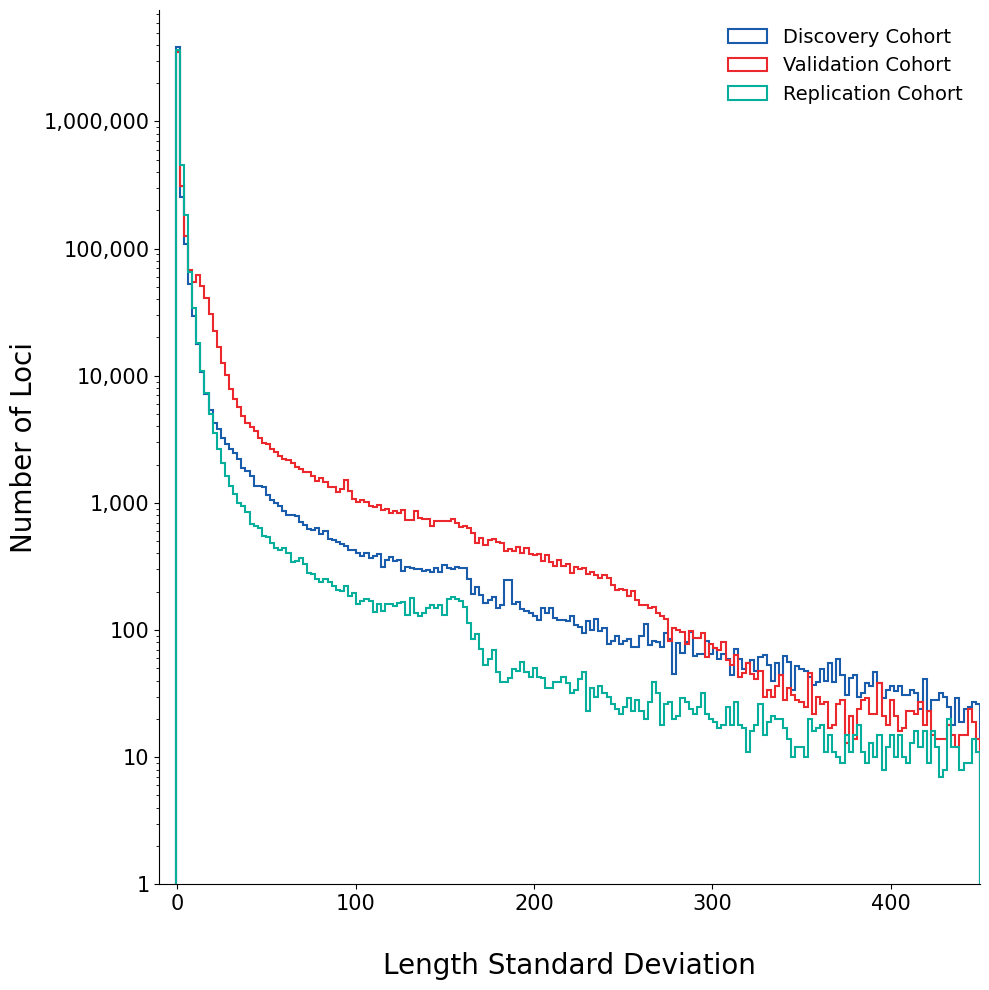

In [1]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

discoveryCohort=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
validationCohort=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
replicationCohort=pd.read_csv('statsTables/ReplicationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

fig, ax = plt.subplots(figsize=(10, 10))

bin_edges = np.linspace(-10, 450, 201)

ax.hist(discoveryCohort.loc[:,'std'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[5], linewidth=1.5,
        label='Discovery Cohort')
ax.hist(validationCohort.loc[:,'std'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[2], linewidth=1.5,
        label='Validation Cohort')
ax.hist(replicationCohort.loc[:,'std'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[6], linewidth=1.5,
        label='Replication Cohort')

ax.set_xlabel('\nLength Standard Deviation', fontsize=20)
ax.set_ylabel('Number of Loci', fontsize=20)
ax.tick_params(labelsize=15)
ax.set_yscale('log')
ax.set_yticks([1, 10, 100, 1000, 10000, 100000, 1000000])
ax.set_yticklabels(['1', '10', '100', '1,000', '10,000', '100,000', '1,000,000'])
ax.set_xlim([-10, 450])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, frameon=False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure1A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure1A.svg')


In [4]:
discoveryVariable=discoveryCohort.loc[discoveryCohort['100thPercentile']>discoveryCohort['0thPercentile'],:]
validationVariable=validationCohort.loc[validationCohort['100thPercentile']>validationCohort['0thPercentile'],:]
replicationVariable=replicationCohort.loc[replicationCohort['100thPercentile']>replicationCohort['0thPercentile'],:]

print(f'discovery: {len(discoveryVariable)}')
print(f'validation: {len(validationVariable)}')
print(f'replication: {len(replicationVariable)}')
combined=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list() + replicationVariable.loc[:,'TRID'].to_list())
combined2=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list())
print(f'combined: {len(combined)}')
print(f'discovery and validation combined: {len(combined2)}')



discovery: 2343357
validation: 4436378
replication: 4315684
combined: 4439522
discovery and validation combined: 4436423


In [7]:
discoveryVariable=discoveryCohort.loc[discoveryCohort['uniqueAlleleSeqs']>1,:]
validationVariable=validationCohort.loc[validationCohort['uniqueAlleleSeqs']>1,:]
replicationVariable=replicationCohort.loc[replicationCohort['uniqueAlleleSeqs']>1,:]

print(f'discovery: {len(discoveryVariable)}')
print(f'validation: {len(validationVariable)}')
print(f'replication: {len(replicationVariable)}')
combined=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list() + replicationVariable.loc[:,'TRID'].to_list())
combined2=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list())
print(f'combined: {len(combined)}')
print(f'discovery and validation combined: {len(combined2)}')



discovery: 2649119
validation: 4437223
replication: 4344365
combined: 4439650
discovery and validation combined: 4437280


In [8]:
discoveryVariable=discoveryCohort.loc[discoveryCohort['uniqueLengths']>1,:]
validationVariable=validationCohort.loc[validationCohort['uniqueLengths']>1,:]
replicationVariable=replicationCohort.loc[replicationCohort['uniqueLengths']>1,:]

print(f'discovery: {len(discoveryVariable)}')
print(f'validation: {len(validationVariable)}')
print(f'replication: {len(replicationVariable)}')
combined=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list() + replicationVariable.loc[:,'TRID'].to_list())
combined2=set(discoveryVariable.loc[:,'TRID'].to_list() + validationVariable.loc[:,'TRID'].to_list())
print(f'combined: {len(combined)}')
print(f'discovery and validation combined: {len(combined2)}')



discovery: 2343357
validation: 4436378
replication: 4315684
combined: 4439522
discovery and validation combined: 4436423


## S1B

In [2]:
import pandas
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
sulovariAbInitio=pandas.read_csv('assets/Sulovari_abInitio_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
codis=pandas.read_csv('assets/CODIS_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])

# split discovery, validation, and replication cohorts into these sets
pathogenicDiscovery=discoveryCohort.merge(pathogenic,how='inner',on='TRID')
abInitioDiscovery=discoveryCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisDiscovery=discoveryCohort.merge(codis,how='inner',on='TRID')
pathogenicValidation=validationCohort.merge(pathogenic,how='inner',on='TRID')
abInitioValidation=validationCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisValidation=validationCohort.merge(codis,how='inner',on='TRID')
pathogenicReplication=replicationCohort.merge(pathogenic,how='inner',on='TRID')
abInitioReplication=replicationCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisReplication=replicationCohort.merge(codis,how='inner',on='TRID')


print(f'discoveryCohort: {len(discoveryCohort)}')
print(f'pathogenicDiscovery: {len(pathogenicDiscovery)}')
print(f'abInitioDiscovery: {len(abInitioDiscovery)}')
print(f'codisDiscovery: {len(codisDiscovery)}')
print(f'validationCohort: {len(validationCohort)}')
print(f'pathogenicValidation: {len(pathogenicValidation)}')
print(f'abInitioValidation: {len(abInitioValidation)}')
print(f'codisValidation: {len(codisValidation)}')
print(f'replicationCohort: {len(replicationCohort)}')
print(f'pathogenicReplication: {len(pathogenicReplication)}')
print(f'abInitioReplication: {len(abInitioReplication)}')
print(f'codisReplication: {len(codisReplication)}')



discoveryCohort: 4439670
pathogenicDiscovery: 53
abInitioDiscovery: 389
codisDiscovery: 20
validationCohort: 4439672
pathogenicValidation: 53
abInitioValidation: 389
codisValidation: 20
replicationCohort: 4435093
pathogenicReplication: 53
abInitioReplication: 389
codisReplication: 20


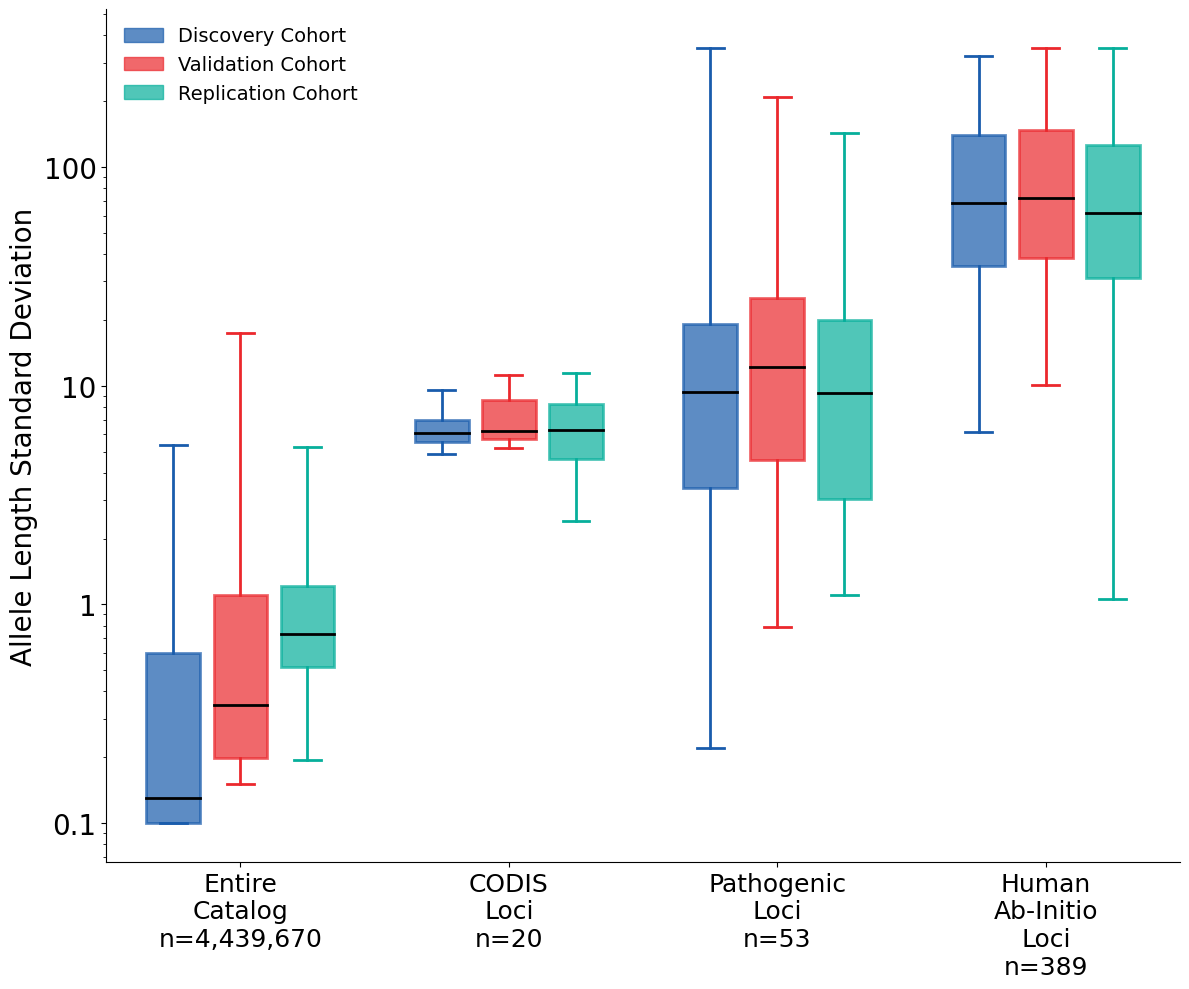

In [3]:
# grouped boxplot of stdev — three cohorts per category
from matplotlib.patches import Patch

colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

cohort_colors = [colorPalette[5], colorPalette[2], colorPalette[6]]  # discovery, validation, replication
cohort_labels = ['Discovery Cohort', 'Validation Cohort', 'Replication Cohort']

# each tuple: (discovery_data, validation_data, replication_data)
categories = [
    (discoveryCohort['std'].values + 0.1,   validationCohort['std'].values + 0.1,   replicationCohort['std'].values + 0.1),
    (codisDiscovery['std'].values + 0.1,     codisValidation['std'].values + 0.1,     codisReplication['std'].values + 0.1),
    (pathogenicDiscovery['std'].values + 0.1, pathogenicValidation['std'].values + 0.1, pathogenicReplication['std'].values + 0.1),
    (abInitioDiscovery['std'].values + 0.1,  abInitioValidation['std'].values + 0.1,  abInitioReplication['std'].values + 0.1)
]
cat_labels = ['Entire\nCatalog\nn=4,439,670', 'CODIS\nLoci\nn=20', 'Pathogenic\nLoci\nn=53', 'Human\nAb-Initio\nLoci\nn=389']

fig, ax = plt.subplots(figsize=(12, 10))

group_centers = np.array([1, 2, 3, 4])
offsets = np.array([-0.25, 0.0, 0.25])
box_width = 0.2

for cohort_idx in range(3):
    positions = group_centers + offsets[cohort_idx]
    data = [categories[cat_idx][cohort_idx] for cat_idx in range(4)]
    bp = ax.boxplot(data, positions=positions, widths=box_width,
                    whis=[5, 95], showfliers=False, patch_artist=True,
                    boxprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    whiskerprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    capprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    medianprops=dict(linewidth=2, color='k'))
    for patch in bp['boxes']:
        patch.set_facecolor(cohort_colors[cohort_idx])
        patch.set_alpha(0.7)

legend_elements = [
    Patch(facecolor=cohort_colors[i], edgecolor=cohort_colors[i], alpha=0.7, label=cohort_labels[i])
    for i in range(3)
]
ax.legend(handles=legend_elements, fontsize=14, frameon=False)

ax.set_xticks(group_centers)
ax.set_xticklabels(cat_labels, fontsize=18)
ax.set_xlim([0.5, 4.5])
ax.set_ylabel('Allele Length Standard Deviation', fontsize=20)
ax.tick_params(axis='y', labelsize=20)
ax.set_yscale('log')
ax.set_yticks([0.1, 1, 10, 100])
ax.set_yticklabels(['0.1', '1', '10', '100'])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure1B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure1B.svg')


In [ ]:
# stats for S1B
# calculate generalized odds ratio for this statistic
import scipy.stats
group1=abInitioDiscovery['std'].dropna().values
group2=discoveryCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1695579751.0
P-Value: 1.3020428591390052e-265
Probability of Superiority: 0.9818
Generalized Odds Ratio: 53.9103


In [5]:
group1=pathogenicDiscovery['std'].dropna().values
group2=discoveryCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 212641630.5
P-Value: 2.570935851550103e-27
Probability of Superiority: 0.9037
Generalized Odds Ratio: 9.3836


In [6]:
group1=codisDiscovery['std'].dropna().values
group2=discoveryCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 85039788.5
P-Value: 3.272729101686258e-14
Probability of Superiority: 0.9577
Generalized Odds Ratio: 22.6555


In [7]:
group1=abInitioValidation['std'].dropna().values
group2=validationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1678532320.5
P-Value: 2.3319398828859008e-228
Probability of Superiority: 0.9719
Generalized Odds Ratio: 34.6089


In [8]:
group1=pathogenicValidation['std'].dropna().values
group2=validationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 209075676.0
P-Value: 5.711541411178619e-23
Probability of Superiority: 0.8885
Generalized Odds Ratio: 7.9718


In [9]:
group1=codisValidation['std'].dropna().values
group2=validationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 79431727.0
P-Value: 4.901068253418528e-10
Probability of Superiority: 0.8946
Generalized Odds Ratio: 8.4847


In [10]:
group1=abInitioReplication['std'].dropna().values
group2=replicationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1653907115.0
P-Value: 7.795633470229725e-216
Probability of Superiority: 0.9586
Generalized Odds Ratio: 23.1821


In [11]:
group1=pathogenicReplication['std'].dropna().values
group2=replicationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 215050048.0
P-Value: 6.404543313020045e-26
Probability of Superiority: 0.9149
Generalized Odds Ratio: 10.7472


In [12]:
group1=codisReplication['std'].dropna().values
group2=replicationCohort['std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 84191332.0
P-Value: 1.7226693953588903e-12
Probability of Superiority: 0.9491
Generalized Odds Ratio: 18.6655


## S1C

In [ ]:
# download the allele length stats tables
import pandas
alleleLengthStats=pandas.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
candidateTRs=alleleLengthStats.loc[((alleleLengthStats['99thPercentile']<175) & (alleleLengthStats['100thPercentile']>175)),:]
candidateTRs.loc[:,'TRID'].to_csv('DiscoveryCohort_175bpCandidates.txt',sep='\t',index=False,header=False)
alleleLengthStats=pandas.read_csv('statsTables/ValidationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
candidateTRs=alleleLengthStats.loc[((alleleLengthStats['99thPercentile']<175) & (alleleLengthStats['100thPercentile']>175)),:]
candidateTRs.loc[:,'TRID'].to_csv('ValidationCohort_175bpCandidates.txt',sep='\t',index=False,header=False)
alleleLengthStats=pandas.read_csv('statsTables/ReplicationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
candidateTRs=alleleLengthStats.loc[((alleleLengthStats['99thPercentile']<175) & (alleleLengthStats['100thPercentile']>175)),:]
candidateTRs.loc[:,'TRID'].to_csv('ReplicationCohort_175bpCandidates.txt',sep='\t',index=False,header=False)


In [ ]:
%%writefile polars_over175_counts.py
import polars as pl
import sys

# ============================================================================
# Configuration
# Pass cohort and chromosome as command-line arguments, e.g.:
#   python polars_over175_counts.py "discoveryCohort" "22" "DiscoveryCohort_175bpCandidates.txt"
# ============================================================================
COHORT     = sys.argv[1] if len(sys.argv) > 1 else "."
CHROM      = sys.argv[2] if len(sys.argv) > 2 else "22"
TRID_FILE  = sys.argv[3] if len(sys.argv) > 3 else "DiscoveryCohort_175bpCandidates.txt"

INPUT_FILE  = f'{COHORT}/alleleInfo_chr{CHROM}_trgt.TR_Explorer_1.0.1.txt.gz'
OUTPUT_FILE = f'{COHORT}_over175_counts_chr{CHROM}.txt'

LENGTH_THRESHOLD = 175

print(f"Processing chromosome {CHROM}")
print(f"Input:  {INPUT_FILE}")
print(f"Output: {OUTPUT_FILE}")

# ============================================================================
# Load target TRIDs
# ============================================================================
target_trids = (
    pl.read_csv(TRID_FILE, separator='\t', has_header=False, new_columns=['TRID'])
    ['TRID'].to_list()
)
print(f"Target TRIDs: {len(target_trids):,}")

# ============================================================================
# Filter to target TRIDs, count alleles with length > 175 per individual
# ============================================================================
result = (
    pl.scan_csv(
        INPUT_FILE,
        separator='\t',
        has_header=True,
        infer_schema_length=0,   # read everything as strings first
    )
    .filter(pl.col('TRID').is_in(target_trids))
    # Parse Allele1_Len and Allele2_Len: '.' -> null (won't count)
    .with_columns([
        pl.when(pl.col('Allele1_Len') == '.')
          .then(None)
          .otherwise(pl.col('Allele1_Len').str.to_integer(strict=False))
          .alias('a1_len'),
        pl.when(pl.col('Allele2_Len') == '.')
          .then(None)
          .otherwise(pl.col('Allele2_Len').str.to_integer(strict=False))
          .alias('a2_len'),
    ])
    # Flag each allele as over threshold (null -> 0)
    .with_columns([
        pl.when(pl.col('a1_len') > LENGTH_THRESHOLD).then(1).otherwise(0).cast(pl.Int32).alias('a1_over175'),
        pl.when(pl.col('a2_len') > LENGTH_THRESHOLD).then(1).otherwise(0).cast(pl.Int32).alias('a2_over175'),
    ])
    .with_columns([
        (pl.col('a1_over175') + pl.col('a2_over175')).alias('over175_count')
    ])
    .select(['SampleID', 'over175_count'])
    .group_by('SampleID')
    .agg(pl.col('over175_count').sum())
    .collect(engine='streaming')
)

result = result.sort('SampleID')

print(f"\nChr {CHROM}: {len(result):,} participants")
print(f"Total over-175 allele counts: {result['over175_count'].sum():,}")

result.write_csv(OUTPUT_FILE, separator='\t')
print(f"Saved: {OUTPUT_FILE}")


In [ ]:
%%bash
for CHROM in {1..22} "X" "Y"; do
python polars_over175_counts.py 'discoveryCohort' ${CHROM} "DiscoveryCohort_175bpCandidates.txt"
python polars_over175_counts.py 'validationCohort' ${CHROM} "ValidationCohort_175bpCandidates.txt"
python polars_over175_counts.py 'replicationCohort' ${CHROM} "ReplicationCohort_175bpCandidates.txt"
done

In [ ]:
# Merge per-chromosome results into one file per cohort
import polars as pl, glob

for cohort, pattern, outfile in [
    ('Discovery',   'discoveryCohort_over175_counts_chr*.txt',  'assets/discoveryCohort_over175_counts.txt'),
    ('Validation',  'validationCohort_over175_counts_chr*.txt', 'assets/validationCohort_over175_counts.txt'),
    ('Replication', 'replicationCohort_over175_counts_chr*.txt',      'assets/replicationCohort_over175_counts.txt'),
]:
    files = glob.glob(pattern)
    combined = (
        pl.concat([pl.read_csv(f, separator='\t') for f in files])
        .group_by('SampleID')
        .agg(pl.col('over175_count').sum())
    )
    combined.write_csv(outfile, separator='\t')
    print(f"{cohort}: {len(combined):,} participants, median over-175 count = {combined['over175_count'].median():.1f}")

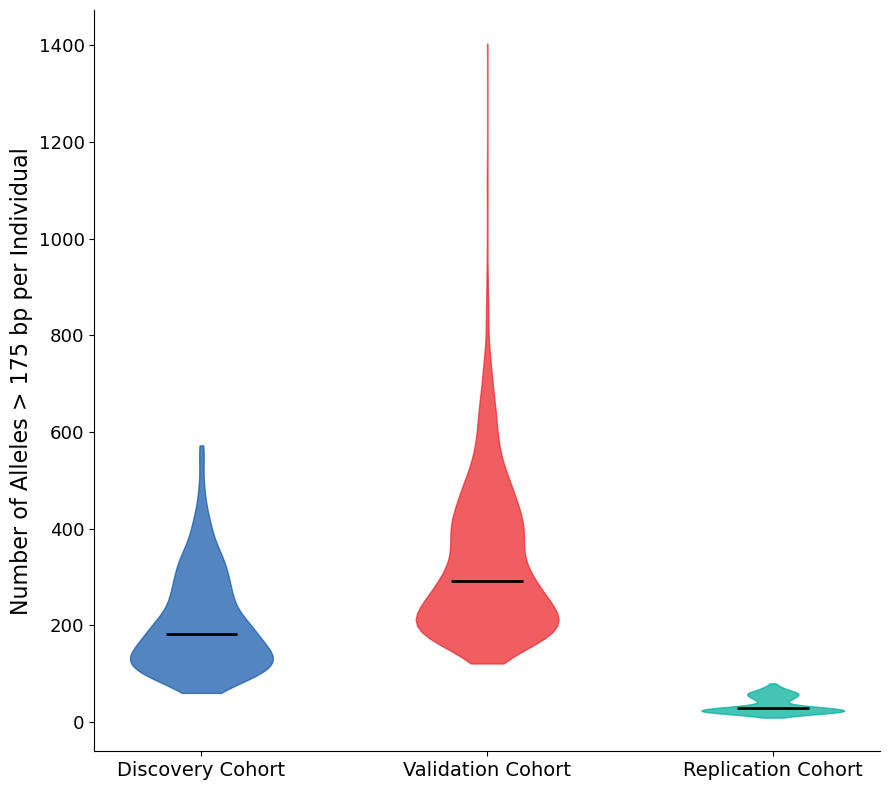

In [3]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

colorPalette  = ['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
cohort_colors = [colorPalette[5], colorPalette[2], colorPalette[6]]   # discovery, validation, replication
cohort_labels = ['Discovery Cohort', 'Validation Cohort', 'Replication Cohort']
cohort_files  = [
    'assets/discoveryCohort_over175_counts.txt',
    'assets/validationCohort_over175_counts.txt',
    'assets/replicationCohort_over175_counts.txt',
]

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

cohort_data = [
    pd.read_csv(f, sep='\t')['over175_count'].values
    for f in cohort_files
]

fig, ax = plt.subplots(figsize=(9, 8))

parts = ax.violinplot(cohort_data, positions=[1, 2, 3], showmedians=True, showextrema=False)

for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(cohort_colors[i])
    pc.set_edgecolor(cohort_colors[i])
    pc.set_alpha(0.75)

parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(cohort_labels, fontsize=14)
ax.set_ylabel('Number of Alleles > 175 bp per Individual', fontsize=16)
ax.tick_params(axis='y', labelsize=13)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure1C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure1C.svg')


# S2: LPS Length Variation

## S2A

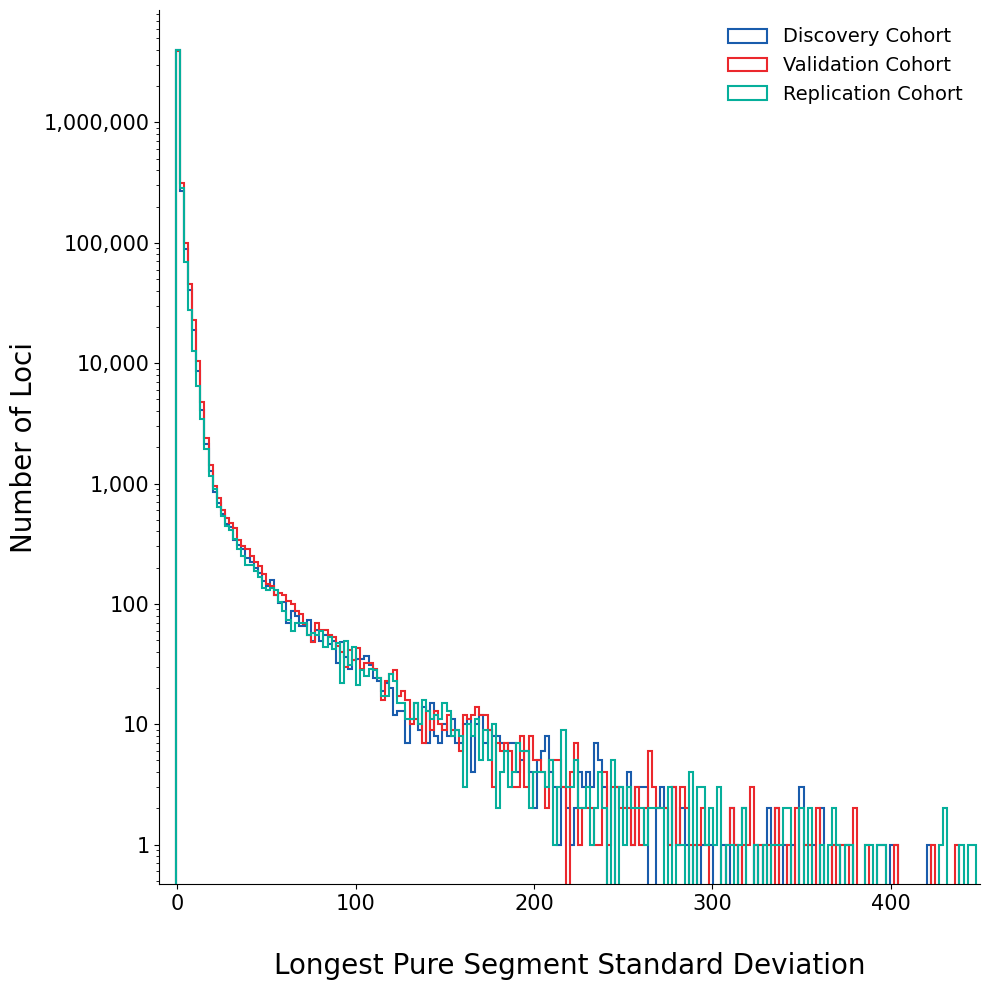

In [ ]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

discoveryCohort=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
validationCohort=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
replicationCohort=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# get weighted mean of the stdev values so we have one value per TRID
discoveryCohort['Stdev_mult']=discoveryCohort.loc[:,'std']*discoveryCohort.loc[:,'N_motif']
discoveryCohort2=discoveryCohort.groupby('TRID').agg(N_motif_summed=("N_motif","sum"),Stdev_summed=("Stdev_mult","sum"))
discoveryCohort2['Stdev_wm']=discoveryCohort2.loc[:,'Stdev_summed']/discoveryCohort2.loc[:,'N_motif_summed']
discoveryCohort=discoveryCohort2.reset_index(drop=False).loc[:,['TRID','N_motif_summed','Stdev_wm']]

validationCohort['Stdev_mult']=validationCohort.loc[:,'std']*validationCohort.loc[:,'N_motif']
validationCohort2=validationCohort.groupby('TRID').agg(N_motif_summed=("N_motif","sum"),Stdev_summed=("Stdev_mult","sum"))
validationCohort2['Stdev_wm']=validationCohort2.loc[:,'Stdev_summed']/validationCohort2.loc[:,'N_motif_summed']
validationCohort=validationCohort2.reset_index(drop=False).loc[:,['TRID','N_motif_summed','Stdev_wm']]

replicationCohort['Stdev_mult']=replicationCohort.loc[:,'std']*replicationCohort.loc[:,'N_motif']
replicationCohort2=replicationCohort.groupby('TRID').agg(N_motif_summed=("N_motif","sum"),Stdev_summed=("Stdev_mult","sum"))
replicationCohort2['Stdev_wm']=replicationCohort2.loc[:,'Stdev_summed']/replicationCohort2.loc[:,'N_motif_summed']
replicationCohort=replicationCohort2.reset_index(drop=False).loc[:,['TRID','N_motif_summed','Stdev_wm']]


colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

fig, ax = plt.subplots(figsize=(10, 10))

bin_edges = np.linspace(-10, 450, 201)

ax.hist(discoveryCohort.loc[:,'Stdev_wm'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[5], linewidth=1.5,
        label='Discovery Cohort')
ax.hist(validationCohort.loc[:,'Stdev_wm'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[2], linewidth=1.5,
        label='Validation Cohort')
ax.hist(replicationCohort.loc[:,'Stdev_wm'].values, bins=bin_edges, density=False,
        histtype='step', color=colorPalette[6], linewidth=1.5,
        label='Replication Cohort')

ax.set_xlabel('\nLongest Pure Segment Standard Deviation', fontsize=20)
ax.set_ylabel('Number of Loci', fontsize=20)
ax.tick_params(labelsize=15)
ax.set_yscale('log')
ax.set_yticks([1, 10, 100, 1000, 10000, 100000, 1000000])
ax.set_yticklabels(['1', '10', '100', '1,000', '10,000', '100,000', '1,000,000'])
ax.set_xlim([-10, 450])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, frameon=False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure2A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure2A.svg')


## S2B

In [3]:
import pandas
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
sulovariAbInitio=pandas.read_csv('assets/Sulovari_abInitio_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
codis=pandas.read_csv('assets/CODIS_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])

# split discovery, validation, and replication cohorts into these sets
pathogenicDiscovery=discoveryCohort.merge(pathogenic,how='inner',on='TRID')
abInitioDiscovery=discoveryCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisDiscovery=discoveryCohort.merge(codis,how='inner',on='TRID')
pathogenicValidation=validationCohort.merge(pathogenic,how='inner',on='TRID')
abInitioValidation=validationCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisValidation=validationCohort.merge(codis,how='inner',on='TRID')
pathogenicReplication=replicationCohort.merge(pathogenic,how='inner',on='TRID')
abInitioReplication=replicationCohort.merge(sulovariAbInitio,how='inner',on='TRID')
codisReplication=replicationCohort.merge(codis,how='inner',on='TRID')


print(f'discoveryCohort: {len(discoveryCohort)}')
print(f'pathogenicDiscovery: {len(pathogenicDiscovery)}')
print(f'abInitioDiscovery: {len(abInitioDiscovery)}')
print(f'codisDiscovery: {len(codisDiscovery)}')
print(f'validationCohort: {len(validationCohort)}')
print(f'pathogenicValidation: {len(pathogenicValidation)}')
print(f'abInitioValidation: {len(abInitioValidation)}')
print(f'codisValidation: {len(codisValidation)}')
print(f'replicationCohort: {len(replicationCohort)}')
print(f'pathogenicReplication: {len(pathogenicReplication)}')
print(f'abInitioReplication: {len(abInitioReplication)}')
print(f'codisReplication: {len(codisReplication)}')



discoveryCohort: 4439661
pathogenicDiscovery: 52
abInitioDiscovery: 389
codisDiscovery: 20
validationCohort: 4439671
pathogenicValidation: 53
abInitioValidation: 389
codisValidation: 20
replicationCohort: 4435089
pathogenicReplication: 52
abInitioReplication: 389
codisReplication: 20


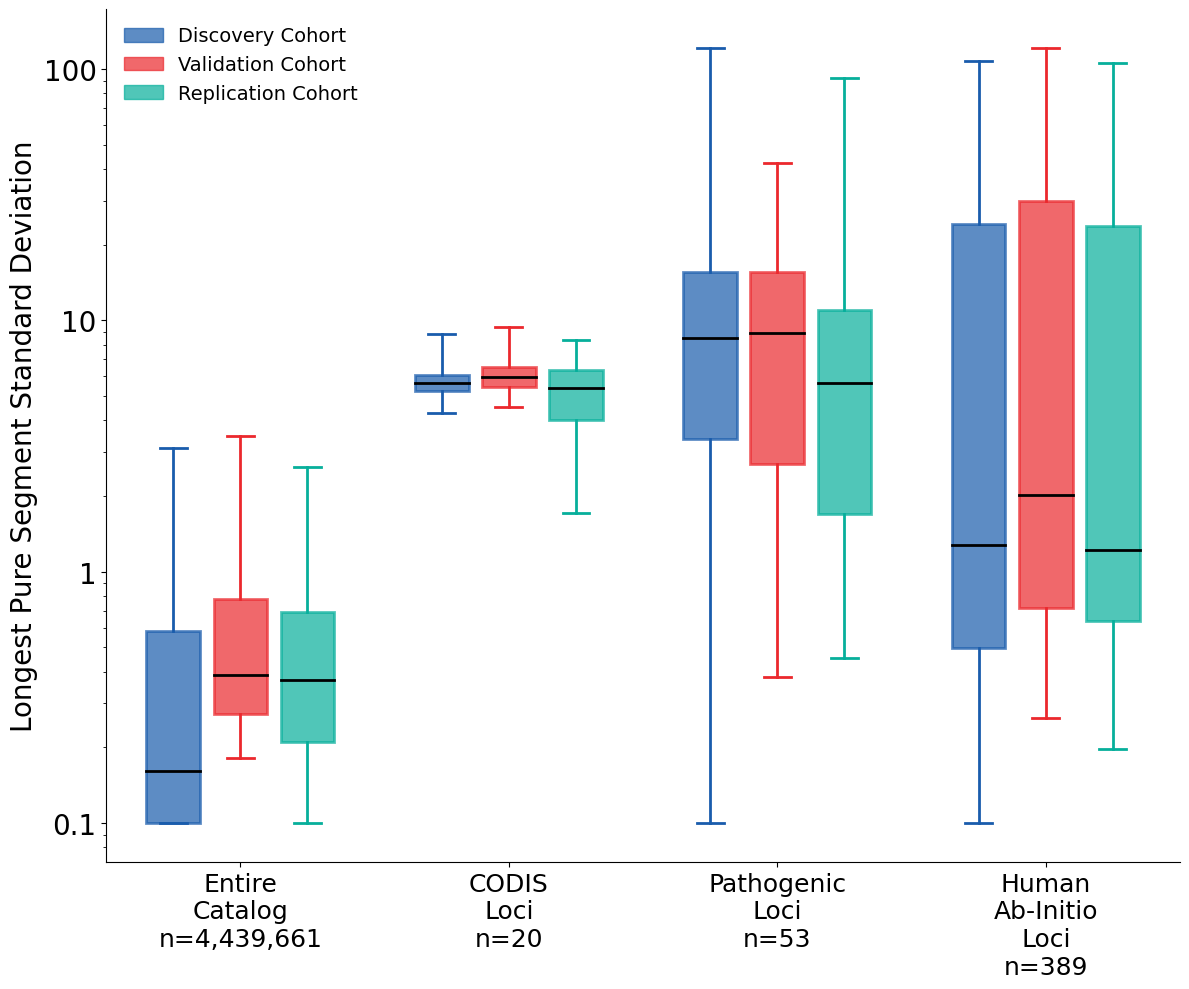

In [4]:
# grouped boxplot of stdev — three cohorts per category
from matplotlib.patches import Patch

colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

cohort_colors = [colorPalette[5], colorPalette[2], colorPalette[6]]  # discovery, validation, replication
cohort_labels = ['Discovery Cohort', 'Validation Cohort', 'Replication Cohort']

# each tuple: (discovery_data, validation_data, replication_data)
categories = [
    (discoveryCohort['Stdev_wm'].values + 0.1,   validationCohort['Stdev_wm'].values + 0.1,   replicationCohort['Stdev_wm'].values + 0.1),
    (codisDiscovery['Stdev_wm'].values + 0.1,     codisValidation['Stdev_wm'].values + 0.1,     codisReplication['Stdev_wm'].values + 0.1),
    (pathogenicDiscovery['Stdev_wm'].values + 0.1, pathogenicValidation['Stdev_wm'].values + 0.1, pathogenicReplication['Stdev_wm'].values + 0.1),
    (abInitioDiscovery['Stdev_wm'].values + 0.1,  abInitioValidation['Stdev_wm'].values + 0.1,  abInitioReplication['Stdev_wm'].values + 0.1)
]
cat_labels = ['Entire\nCatalog\nn=4,439,661', 'CODIS\nLoci\nn=20', 'Pathogenic\nLoci\nn=53', 'Human\nAb-Initio\nLoci\nn=389']

fig, ax = plt.subplots(figsize=(12, 10))

group_centers = np.array([1, 2, 3, 4])
offsets = np.array([-0.25, 0.0, 0.25])
box_width = 0.2

for cohort_idx in range(3):
    positions = group_centers + offsets[cohort_idx]
    data = [categories[cat_idx][cohort_idx] for cat_idx in range(4)]
    bp = ax.boxplot(data, positions=positions, widths=box_width,
                    whis=[5, 95], showfliers=False, patch_artist=True,
                    boxprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    whiskerprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    capprops=dict(linewidth=2, color=cohort_colors[cohort_idx]),
                    medianprops=dict(linewidth=2, color='k'))
    for patch in bp['boxes']:
        patch.set_facecolor(cohort_colors[cohort_idx])
        patch.set_alpha(0.7)

legend_elements = [
    Patch(facecolor=cohort_colors[i], edgecolor=cohort_colors[i], alpha=0.7, label=cohort_labels[i])
    for i in range(3)
]
ax.legend(handles=legend_elements, fontsize=14, frameon=False)

ax.set_xticks(group_centers)
ax.set_xticklabels(cat_labels, fontsize=18)
ax.set_xlim([0.5, 4.5])
ax.set_ylabel('Longest Pure Segment Standard Deviation', fontsize=20)
ax.tick_params(axis='y', labelsize=20)
ax.set_yscale('log')
ax.set_yticks([0.1, 1, 10, 100])
ax.set_yticklabels(['0.1', '1', '10', '100'])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure2B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure2B.svg')


In [5]:
# stats for 2B
# calculate generalized odds ratio for this statistic
import scipy.stats
group1=abInitioDiscovery['Stdev_wm'].dropna().values
group2=discoveryCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1413896136.5
P-Value: 7.328428209766468e-116
Probability of Superiority: 0.8187
Generalized Odds Ratio: 4.5153


In [6]:
group1=pathogenicDiscovery['Stdev_wm'].dropna().values
group2=discoveryCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 204722344.0
P-Value: 1.842638307238108e-24
Probability of Superiority: 0.8868
Generalized Odds Ratio: 7.8318


In [7]:
group1=codisDiscovery['Stdev_wm'].dropna().values
group2=discoveryCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 86597933.5
P-Value: 5.492475525562861e-15
Probability of Superiority: 0.9753
Generalized Odds Ratio: 39.4472


In [8]:
group1=abInitioValidation['Stdev_wm'].dropna().values
group2=validationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1411823821.0
P-Value: 1.2599430137705334e-104
Probability of Superiority: 0.8175
Generalized Odds Ratio: 4.4790


In [9]:
group1=pathogenicValidation['Stdev_wm'].dropna().values
group2=validationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 211603887.5
P-Value: 3.767800260964272e-24
Probability of Superiority: 0.8993
Generalized Odds Ratio: 8.9289


In [10]:
group1=codisValidation['Stdev_wm'].dropna().values
group2=validationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 86469454.0
P-Value: 1.0641138214822881e-13
Probability of Superiority: 0.9738
Generalized Odds Ratio: 37.2077


In [11]:
group1=abInitioReplication['Stdev_wm'].dropna().values
group2=replicationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")


Raw U Statistic: 1400143042.0
P-Value: 3.192154738651411e-101
Probability of Superiority: 0.8116
Generalized Odds Ratio: 4.3067


In [12]:
group1=pathogenicReplication['Stdev_wm'].dropna().values
group2=replicationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 209878745.0
P-Value: 5.187445633328804e-25
Probability of Superiority: 0.9100
Generalized Odds Ratio: 10.1166


In [13]:
group1=codisReplication['Stdev_wm'].dropna().values
group2=replicationCohort['Stdev_wm'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 86194942.0
P-Value: 1.218827999954159e-13
Probability of Superiority: 0.9717
Generalized Odds Ratio: 34.3839


## S2C

In [ ]:
# initial data loading and package import
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
discoveryCohort=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
validationCohort=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
replicationCohort=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
catalog=pd.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['Chrom','Start','Stop','Info'])

# groom the catalog dataframe
catalog[['TRID','MOTIFS','STRUC']]=catalog.loc[:,'Info'].str.split(';',expand=True)
catalog['TRID']=catalog.loc[:,'TRID'].str[3:]
catalog['MOTIFS']=catalog.loc[:,'MOTIFS'].str[7:].str.split(',',expand=False)
catalog['STRUC']=catalog.loc[:,'STRUC'].str[6:]
catalog=catalog.loc[:,['TRID','MOTIFS']]
catalog2=catalog.loc[catalog['TRID'].isin(discoveryCohort.loc[:,'TRID'].values),:].reset_index(drop=True)
catalog2=catalog2.loc[:,['TRID','MOTIFS']].explode('MOTIFS').reset_index(drop=True)
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    return(min(motifs))

# apply the simplest_motif function to both the catalog and lps dataframes
catalog2['simpleMotif']=catalog2.loc[:,'MOTIFS'].apply(simplest_motif)

discoveryCohort['simpleMotif']=discoveryCohort.loc[:,'LPS_Motif'].apply(simplest_motif)
validationCohort['simpleMotif']=validationCohort.loc[:,'LPS_Motif'].apply(simplest_motif)
replicationCohort['simpleMotif']=replicationCohort.loc[:,'LPS_Motif'].apply(simplest_motif)

# merge to see which motifs observed as lps are in the catalog
discoveryCohort=discoveryCohort.loc[:,['TRID','simpleMotif','N_motif']].merge(catalog2.loc[:,['TRID','simpleMotif']],how='left',on=['TRID','simpleMotif'],indicator=True)
discoveryCohort['refMotif']=0
discoveryCohort.loc[discoveryCohort['_merge']=='both','refMotif']=1
discoveryCohort=discoveryCohort.drop(columns='_merge')
discoveryCohort=discoveryCohort.drop_duplicates(keep='first')

validationCohort=validationCohort.loc[:,['TRID','simpleMotif','N_motif']].merge(catalog2.loc[:,['TRID','simpleMotif']],how='left',on=['TRID','simpleMotif'],indicator=True)
validationCohort['refMotif']=0
validationCohort.loc[validationCohort['_merge']=='both','refMotif']=1
validationCohort=validationCohort.drop(columns='_merge')
validationCohort=validationCohort.drop_duplicates(keep='first')

replicationCohort=replicationCohort.loc[:,['TRID','simpleMotif','N_motif']].merge(catalog2.loc[:,['TRID','simpleMotif']],how='left',on=['TRID','simpleMotif'],indicator=True)
replicationCohort['refMotif']=0
replicationCohort.loc[replicationCohort['_merge']=='both','refMotif']=1
replicationCohort=replicationCohort.drop(columns='_merge')
replicationCohort=replicationCohort.drop_duplicates(keep='first')

# simulate sampling alleles and counting novel motifs observed
n_discovery=discoveryCohort.loc[:,'N_motif'].max()
discoveryNovelMotifsObserved=np.zeros(n_discovery)
choiceVals=discoveryCohort.loc[discoveryCohort['refMotif']==0,'N_motif'].apply(lambda x: np.argmax(np.random.choice(n_discovery,n_discovery,replace=False)<x))
for val in choiceVals:
    discoveryNovelMotifsObserved[val]+=1

n_validation=validationCohort.loc[:,'N_motif'].max()
validationNovelMotifsObserved=np.zeros(n_validation)
choiceVals=validationCohort.loc[validationCohort['refMotif']==0,'N_motif'].apply(lambda x: np.argmax(np.random.choice(n_validation,n_validation,replace=False)<x))
for val in choiceVals:
    validationNovelMotifsObserved[val]+=1

n_replication=replicationCohort.loc[:,'N_motif'].max()
replicationNovelMotifsObserved=np.zeros(n_replication)
choiceVals=replicationCohort.loc[replicationCohort['refMotif']==0,'N_motif'].apply(lambda x: np.argmax(np.random.choice(n_replication,n_replication,replace=False)<x))
for val in choiceVals:
    replicationNovelMotifsObserved[val]+=1


In [3]:
discoveryNovelMotifsObserved[-10:].mean()

57.5

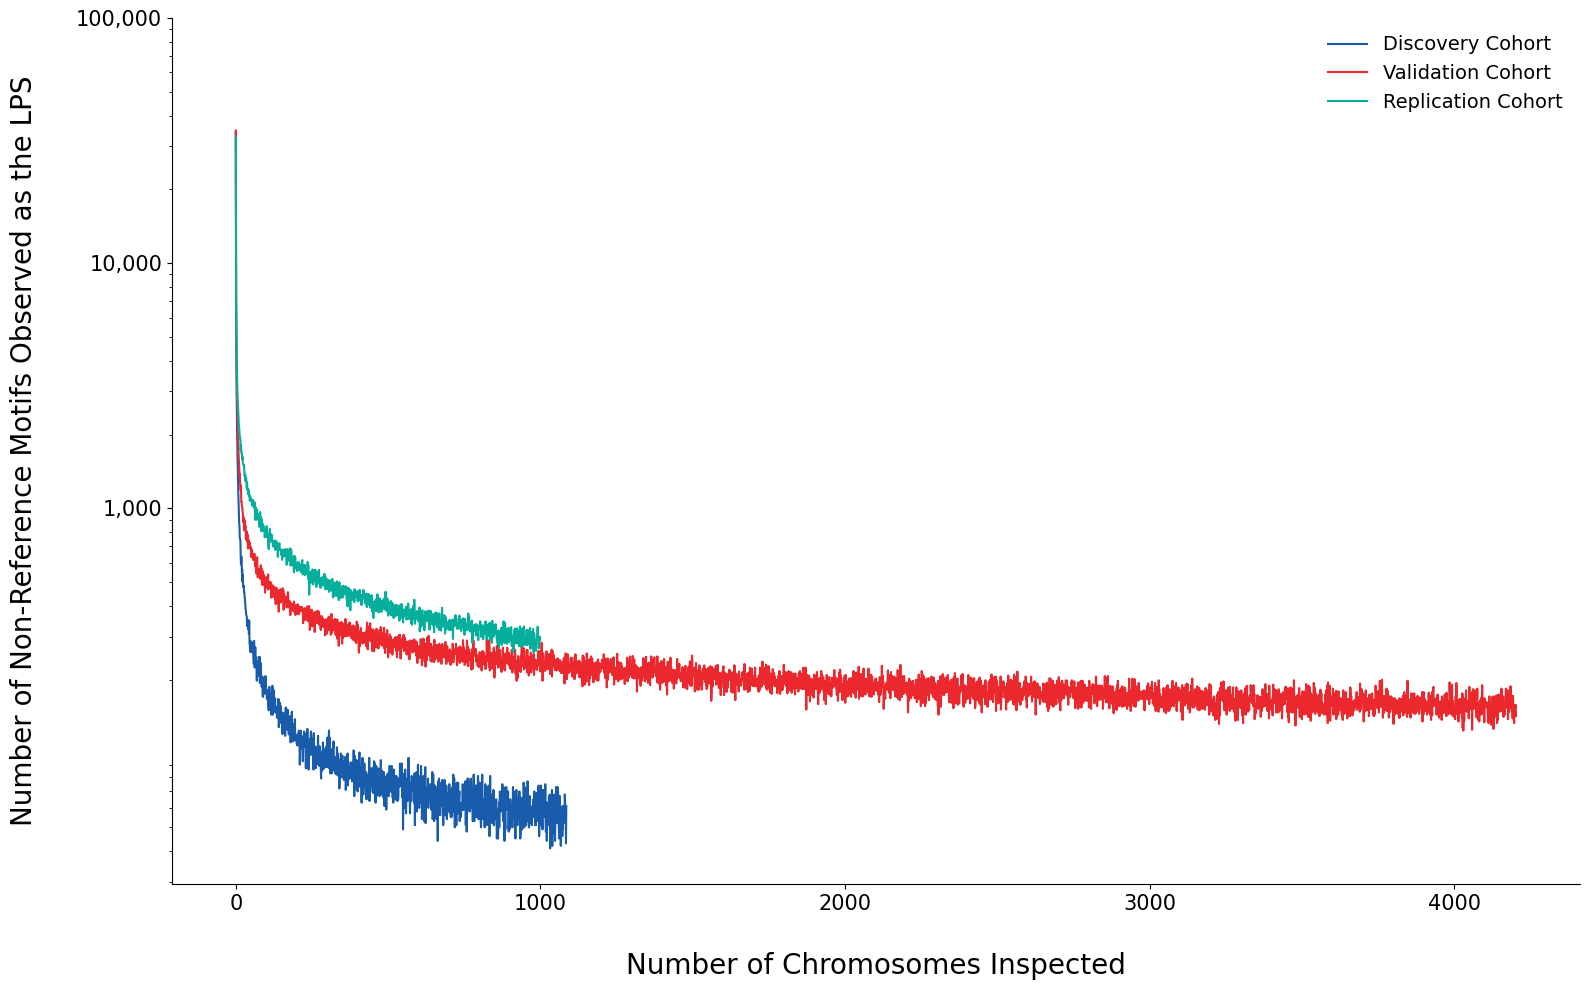

In [4]:
# plot the saturation curve
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
fig, ax = plt.subplots(figsize=(16, 10))
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
plt.plot(discoveryNovelMotifsObserved,c=colorPalette[5],label='Discovery Cohort')
plt.plot(validationNovelMotifsObserved,c=colorPalette[2],label='Validation Cohort')
plt.plot(replicationNovelMotifsObserved,c=colorPalette[6],label='Replication Cohort')
plt.ylabel('Number of Non-Reference Motifs Observed as the LPS\n',fontsize=20)
plt.xlabel('\nNumber of Chromosomes Inspected',fontsize=20)
plt.yscale('log')
ax.legend(fontsize=14, frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([1000,10000,100000])
ax.set_yticklabels(['1,000' , '10,000' , '100,000'])
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure2C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure2C.svg')

# S3: LPS Variation by Motif Length

## S3A

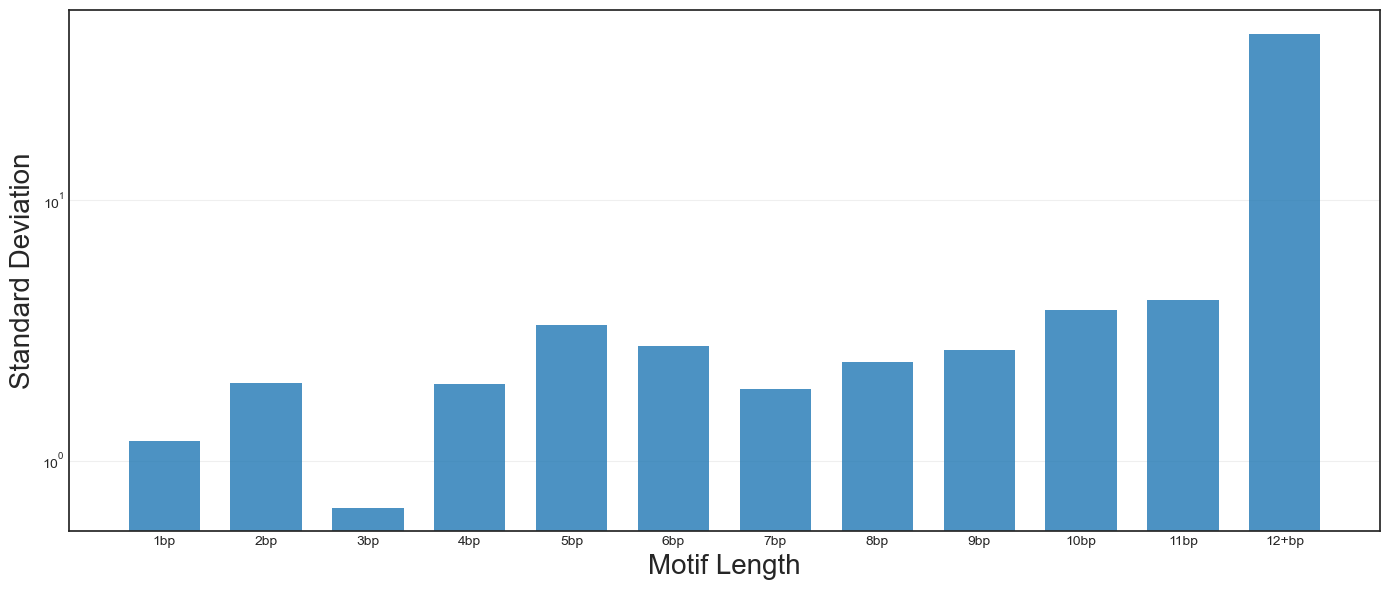

In [ ]:
# Motif Length Analysis - STD Distribution by Motif Length
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# Select most common LPS motif per TR
lps_common = lps.sort_values(by=['TRID', 'N_motif'], ascending=False).drop_duplicates(subset='TRID', keep='first').reset_index(drop=True)

# Define motif standardization functions
def complement(seq):
    complement_dict = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'}
    bases = list(seq)
    bases = [complement_dict[base] for base in bases]
    return ''.join(bases)

def reverse_complement(seq):
    return complement(seq[::-1])

def simplest_motif(motif):
    # Find smallest repeating unit
    i = (motif + motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    
    # Get all rotations
    motifs = []
    for i in range(len(motif)):
        c = motif[i:] + motif[:i]
        motifs.append(c.upper())
    
    # Get all rotations of reverse complement
    motifRC = reverse_complement(motif.upper())
    i = (motifRC + motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    
    for i in range(len(motifRC)):
        c = motifRC[i:] + motifRC[:i]
        motifs.append(c)
    
    # Return lexicographically smallest
    return min(motifs)

# Standardize motif names
lps_common['simpleMotif'] = lps_common['LPS_Motif'].apply(simplest_motif)

# Calculate motif length
lps_common['motifLen'] = lps_common['simpleMotif'].str.len()

# Group lengths >11bp as "12+bp"
lps_common['motifLenGroup'] = lps_common['motifLen'].apply(lambda x: '12+bp' if x > 11 else f'{x}bp')

# Calculate statistics for each motif length group
motif_length_order = [f'{i}bp' for i in range(1, 12)] + ['12+bp']
stats_by_length = []

for length_group in motif_length_order:
    subset = lps_common[lps_common['motifLenGroup'] == length_group]
    if len(subset) > 0:
        stats_by_length.append({
            'MotifLength': length_group,
            'Median': subset['std'].median(),
            '99th_Percentile': subset['std'].quantile(0.99),
            '99.9th_Percentile': subset['std'].quantile(0.999),
            'Standard_Deviation': subset['std'].dropna().std(),
            'N': len(subset)
        })

stats_df = pd.DataFrame(stats_by_length)

# Create grouped bar plot
fig, ax = plt.subplots(figsize=(14, 6))

stats_df2=stats_df
x = np.arange(len(stats_df2))
width = 0.7


bars4 = ax.bar(x, stats_df2['Standard_Deviation'], width, label='Standard Deviation', alpha=0.8)

ax.set_xlabel('Motif Length', fontsize=20)
ax.set_ylabel('Standard Deviation', fontsize=20)
#ax.set_title('Distribution of most common LPS Standard Deviation by Motif Length', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(stats_df2['MotifLength'], rotation=0)
#ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.yscale('log')

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure3A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure3A.svg')

## S3B

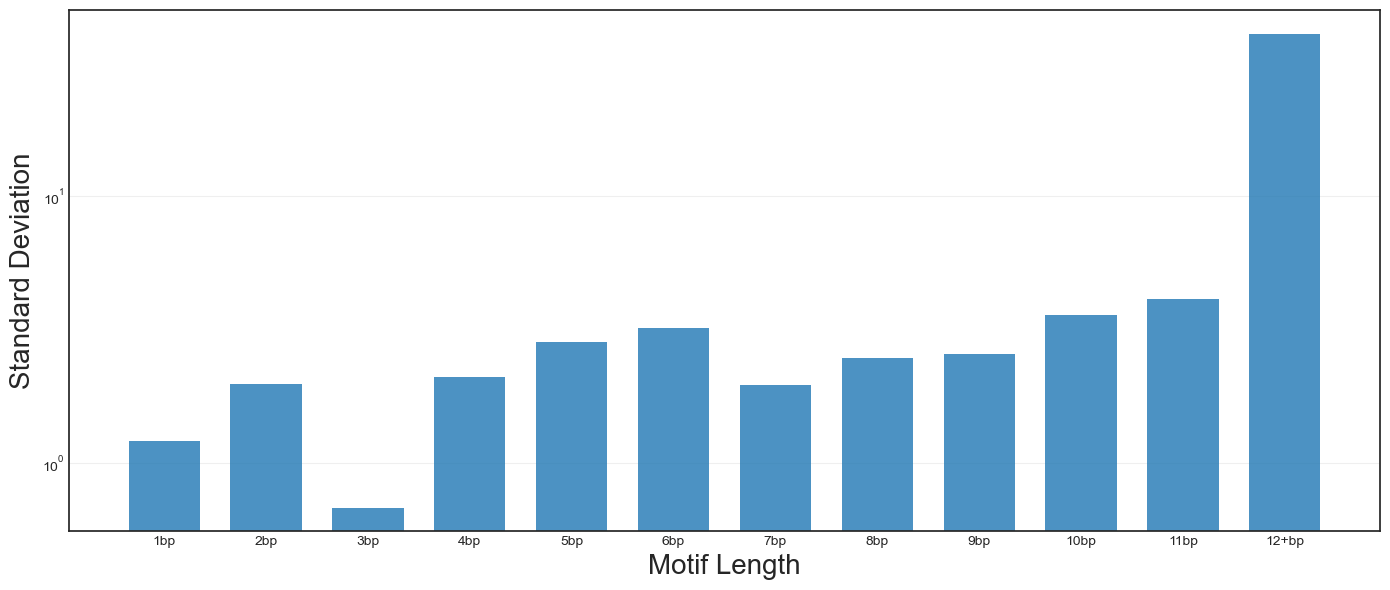

In [17]:
# plot again with the intergenic loci only
annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
lps_common['motifLenGroup'] = lps_common['motifLen'].apply(lambda x: '12+bp' if x > 11 else f'{x}bp')
lps_common2=lps_common.merge(annotations,how='inner',on='TRID')
lps_common3=lps_common2.loc[lps_common2['region']=='intergenic',:]

# Calculate statistics for each motif length group
motif_length_order = [f'{i}bp' for i in range(1, 12)] + ['12+bp']
stats_by_length = []

for length_group in motif_length_order:
    subset = lps_common3[lps_common3['motifLenGroup'] == length_group]
    if len(subset) > 0:
        stats_by_length.append({
            'MotifLength': length_group,
            'Median': subset['std'].median(),
            '99th_Percentile': subset['std'].quantile(0.99),
            '99.9th_Percentile': subset['std'].quantile(0.999),
            'Standard_Deviation': subset['std'].dropna().std(),
            'N': len(subset)
        })

stats_df = pd.DataFrame(stats_by_length)
# Create grouped bar plot
fig, ax = plt.subplots(figsize=(14, 6))

stats_df2=stats_df
x = np.arange(len(stats_df2))
width = 0.7


bars4 = ax.bar(x, stats_df2['Standard_Deviation'], width, label='Standard Deviation', alpha=0.8)

ax.set_xlabel('Motif Length', fontsize=20)
ax.set_ylabel('Standard Deviation', fontsize=20)
#ax.set_title('Distribution of most common LPS Standard Deviation by Motif Length', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(stats_df2['MotifLength'], rotation=0)
#ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.yscale('log')

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure3B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure3B.svg')

# S4: LPS Motif Variation

## S4A

In [ ]:
import pandas
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
discoveryCohort=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
catalog=pandas.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['Chrom','Start','Stop','Info'])

# groom the catalog dataframe
catalog[['TRID','MOTIFS','STRUC']]=catalog.loc[:,'Info'].str.split(';',expand=True)
catalog['TRID']=catalog.loc[:,'TRID'].str[3:]
catalog['MOTIFS']=catalog.loc[:,'MOTIFS'].str[7:].str.split(',',expand=False)
catalog['STRUC']=catalog.loc[:,'STRUC'].str[6:]
catalog=catalog.loc[:,['TRID','MOTIFS']]
catalog2=catalog.loc[catalog['TRID'].isin(discoveryCohort.loc[:,'TRID'].values),:].reset_index(drop=True)
catalog2=catalog2.loc[:,['TRID','MOTIFS']].explode('MOTIFS').reset_index(drop=True)
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    return(min(motifs))

# apply the simplest_motif function to both the catalog and lps dataframes
catalog2['simpleMotif']=catalog2.loc[:,'MOTIFS'].apply(simplest_motif)

discoveryCohort['simpleMotif']=discoveryCohort.loc[:,'LPS_Motif'].apply(simplest_motif)

# merge to see which motifs observed as lps are in the catalog
discoveryCohort=discoveryCohort.loc[:,['TRID','simpleMotif','N_motif']].merge(catalog2,how='left',on=['TRID','simpleMotif'],indicator=True)

novelMotifs=discoveryCohort.loc[discoveryCohort['_merge']=='left_only',:].reset_index(drop=True)
refMotifs=discoveryCohort.loc[discoveryCohort['_merge']=='both',:].reset_index(drop=True)

refMotifs['N_refMotifLPS']=refMotifs.loc[:,'N_motif']
refMotifs['N_nonRefMotifLPS']=0
refMotifs['N_nonRefMotifLPSSamePeriodicity']=0
refMotifs['N_nonRefMotifLPSNovelPeriodicity']=0
refMotifs['N_nonRefMotifLPSInterleaved']=0

novelMotifs=novelMotifs.drop(columns='MOTIFS').merge(catalog2.loc[:,['TRID','MOTIFS']],how='inner',on='TRID')
novelMotifs['N_refMotifLPS']=0

from tqdm import tqdm
tqdm.pandas()

def getMotifNovelty(row):
    thisTRID=row.loc['TRID']
    refMotifs=row.loc['MOTIFS']
    observedMotif=row.loc['simpleMotif']
    thisMotifCount=row.loc['N_motif']
    nNonRefMotifLPSSamePeriodicity=0
    nNonRefMotifLPSNovelPeriodicity=0
    nNonRefMotifLPSInterleaved=0
    if min([min([len(observedMotif) % len(x) for x in refMotifs]),min([len(x) % len(observedMotif) for x in refMotifs])])==0:
        nNonRefMotifLPSSamePeriodicity = thisMotifCount
        if min([min([len(observedMotif) / len(x) for x in refMotifs]),min([len(x) / len(observedMotif) for x in refMotifs])])!=1:
            nNonRefMotifLPSInterleaved = thisMotifCount
    else:
        nNonRefMotifLPSNovelPeriodicity = thisMotifCount
    return nNonRefMotifLPSSamePeriodicity, nNonRefMotifLPSNovelPeriodicity, nNonRefMotifLPSInterleaved
novelMotifs['N_nonRefMotifLPSSamePeriodicity'], novelMotifs['N_nonRefMotifLPSNovelPeriodicity'], novelMotifs['N_nonRefMotifLPSInterleaved'] = zip(*novelMotifs.progress_apply(getMotifNovelty,axis=1))
novelMotifs=novelMotifs.rename(columns={'N_motif':'N_nonRefMotifLPS'})
novelMotifs2=novelMotifs.loc[:,['TRID','N_refMotifLPS','N_nonRefMotifLPS','N_nonRefMotifLPSSamePeriodicity','N_nonRefMotifLPSNovelPeriodicity','N_nonRefMotifLPSInterleaved']].groupby('TRID').sum().reset_index(drop=False)

refMotifs2=refMotifs.loc[:,['TRID','N_refMotifLPS','N_nonRefMotifLPS','N_nonRefMotifLPSSamePeriodicity','N_nonRefMotifLPSNovelPeriodicity','N_nonRefMotifLPSInterleaved']].groupby('TRID').sum().reset_index(drop=False)

combined=pandas.concat([novelMotifs2,refMotifs2],ignore_index=True).groupby('TRID').sum().reset_index(drop=False)


100%|██████████| 184796/184796 [00:04<00:00, 45836.26it/s]


In [12]:
print(str(pctNovelNever))
print(str(pctNovel1Percent))
print(str(pctNovel10Percent))
print(str(pctNovel50Percent))
print(str(pctNovel90Percent))
print(str(pctNovelUbiquitous))


96.6556680791619
1.74459266146672
0.5330812420137484
0.3483824553271072
0.20055585325095768
0.5472039419225927


C:\Users\Matt\AppData\Local\Temp\ipykernel_104108\1563196892.py:8: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


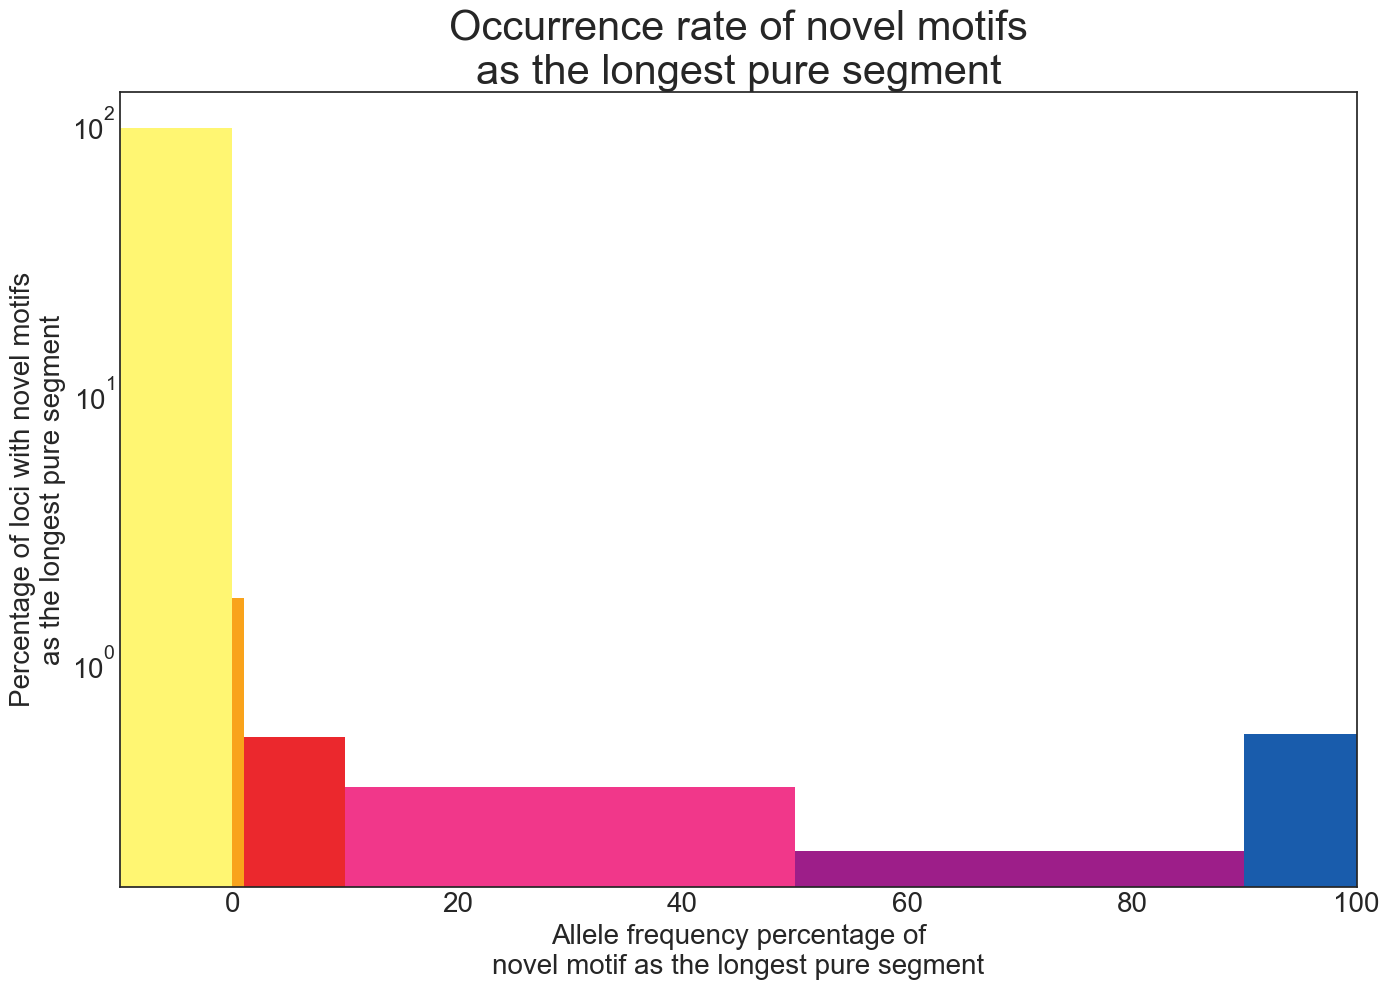

In [11]:
n_cohort=2*543
pctNovelNever=100*len(combined.loc[combined['N_nonRefMotifLPS']==0,:])/len(combined)
pctNovel1Percent=100*len(combined.loc[((combined['N_nonRefMotifLPS']>0) & (combined['N_nonRefMotifLPS']<0.01*n_cohort)),:])/len(combined)
pctNovel10Percent=100*len(combined.loc[((combined['N_nonRefMotifLPS']>(0.01*n_cohort)-1) & (combined['N_nonRefMotifLPS']<(0.1*n_cohort))),:])/len(combined)
pctNovel50Percent=100*len(combined.loc[((combined['N_nonRefMotifLPS']>(0.1*n_cohort)-1) & (combined['N_nonRefMotifLPS']<(0.5*n_cohort))),:])/len(combined)
pctNovel90Percent=100*len(combined.loc[((combined['N_nonRefMotifLPS']>(0.5*n_cohort)-1) & (combined['N_nonRefMotifLPS']<(0.9*n_cohort))),:])/len(combined)
pctNovelUbiquitous=100*len(combined.loc[combined['N_nonRefMotifLPS']>(0.9*n_cohort)-1,:])/len(combined)
plt.style.use('seaborn-white')
plt.figure(figsize=(14, 10))
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B']
labels=['No alt motifs','<1% alt motifs','1-10% alt motifs','10-50% alt motifs','50-90% alt motifs','>90% alt motifs']
plt.bar(x=[-10,0,1,10,50,90],height=[pctNovelNever,pctNovel1Percent,pctNovel10Percent,pctNovel50Percent,pctNovel90Percent,pctNovelUbiquitous],width=[10,1,9,40,40,10],
        align='edge',color=colorPalette[:6])
plt.title('Occurrence rate of novel motifs\nas the longest pure segment',fontsize=30)
plt.ylabel('Percentage of loci with novel motifs\nas the longest pure segment',fontsize=20)
plt.xlabel('Allele frequency percentage of\nnovel motif as the longest pure segment',fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim([-10,100])
plt.yscale('log')
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure4A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure4A.svg')

## S4C

In [41]:
novelMotifLoci=combined.loc[combined['N_nonRefMotifLPS']>0,:]
numInterleaved=novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
numSubstitutions=novelMotifLoci.loc[:,'N_nonRefMotifLPSSamePeriodicity'].sum()-novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
print('Interleaved: ',str(numInterleaved))
print('Substitution: ',str(numSubstitutions))


Interleaved:  28026337
Substitution:  15925716


In [42]:
novelMotifLoci=combined.loc[((combined['N_nonRefMotifLPS']>0) & (combined['N_nonRefMotifLPS']<(0.1*n_cohort))),:]
numInterleaved=novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
numSubstitutions=novelMotifLoci.loc[:,'N_nonRefMotifLPSSamePeriodicity'].sum()-novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
print('Interleaved: ',str(numInterleaved))
print('Substitution: ',str(numSubstitutions))


Interleaved:  586973
Substitution:  470533


In [43]:
novelMotifLoci=combined.loc[((combined['N_nonRefMotifLPS']>0) & (combined['N_nonRefMotifLPS']>(0.9*n_cohort))),:]
numInterleaved=novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
numSubstitutions=novelMotifLoci.loc[:,'N_nonRefMotifLPSSamePeriodicity'].sum()-novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
print('Interleaved: ',str(numInterleaved))
print('Substitution: ',str(numSubstitutions))


Interleaved:  21380851
Substitution:  10353576


Interleaved:  586973
Substitution:  470533


C:\Users\Matt\AppData\Local\Temp\ipykernel_79456\1030740687.py:11: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


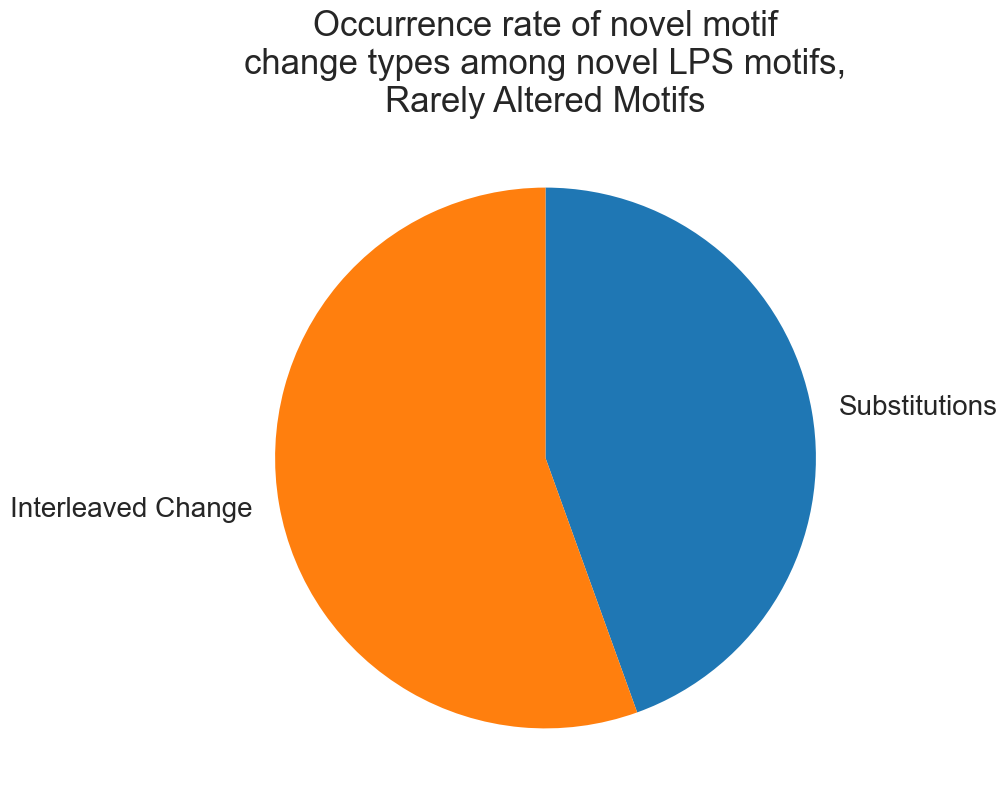

In [46]:
import matplotlib.pyplot as plt
# none of the detected novel motifs are period changes. Make a pie chart comparing the substitutions to the interleaved changes
novelMotifLoci=combined.loc[((combined['N_nonRefMotifLPS']>0) & (combined['N_nonRefMotifLPS']<(0.1*n_cohort))),:]
numInterleaved=novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
numSubstitutions=novelMotifLoci.loc[:,'N_nonRefMotifLPSSamePeriodicity'].sum()-novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
print('Interleaved: ',str(numInterleaved))
print('Substitution: ',str(numSubstitutions))


from matplotlib import pyplot as plt
plt.style.use('seaborn-white')
plt.figure(figsize=(10, 10))
plt.pie([numSubstitutions,numInterleaved],
        labels=['Substitutions','Interleaved Change'],
        startangle=90, counterclock=False, textprops={'fontsize': 20})
plt.title('Occurrence rate of novel motif\nchange types among novel LPS motifs,\nRarely Altered Motifs',fontsize=25)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure4C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure4C.svg')

## S4D

Interleaved:  21380851
Substitution:  10353576


C:\Users\Matt\AppData\Local\Temp\ipykernel_79456\4019401186.py:11: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


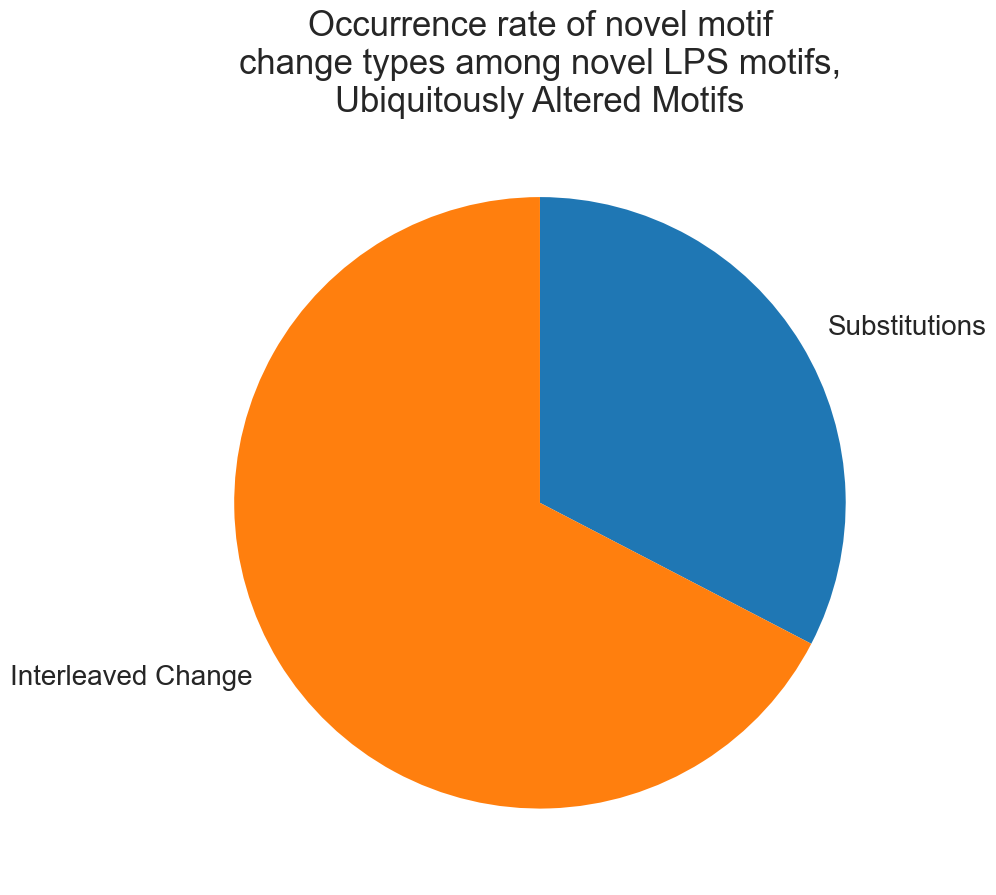

In [48]:
import matplotlib.pyplot as plt
# none of the detected novel motifs are period changes. Make a pie chart comparing the substitutions to the interleaved changes
novelMotifLoci=combined.loc[((combined['N_nonRefMotifLPS']>0) & (combined['N_nonRefMotifLPS']>(0.9*n_cohort))),:]
numInterleaved=novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
numSubstitutions=novelMotifLoci.loc[:,'N_nonRefMotifLPSSamePeriodicity'].sum()-novelMotifLoci.loc[:,'N_nonRefMotifLPSInterleaved'].sum()
print('Interleaved: ',str(numInterleaved))
print('Substitution: ',str(numSubstitutions))


from matplotlib import pyplot as plt
plt.style.use('seaborn-white')
plt.figure(figsize=(10, 10))
plt.pie([numSubstitutions,numInterleaved],
        labels=['Substitutions','Interleaved Change'],
        startangle=90, counterclock=False, textprops={'fontsize': 20})
plt.title('Occurrence rate of novel motif\nchange types among novel LPS motifs,\nUbiquitously Altered Motifs',fontsize=25)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure4D.png',dpi=600)
plt.savefig('figures/SupplementaryFigure4D.svg')